In [1]:
 %pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

  Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl (10.9 MB)
Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl (8.4 MB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached joblib-1.6.0-py3-none-any.whl (3


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

In [3]:
df.shape

(891, 15)

In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [6]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
df.describe()             
df.duplicated().sum()     

np.int64(107)

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["survived"])
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [9]:
pct = (X_train.isnull().mean() * 100).round(1).sort_values(ascending=False)
pct[pct > 0]

deck           77.7
age            19.2
embarked        0.3
embark_town     0.3
dtype: float64

In [10]:
cols_a_supprimer = pct[pct > 40].index.tolist()
print("Colonnes supprimées :", cols_a_supprimer)

X_train = X_train.drop(columns=cols_a_supprimer)
X_test = X_test.drop(columns=cols_a_supprimer)

Colonnes supprimées : ['deck']


In [ ]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

for col in num_cols:
    if X_train[col].isnull().any() or X_test[col].isnull().any():
        med = X_train[col].median()          
        X_train[col] = X_train[col].fillna(med)
        X_test[col] = X_test[col].fillna(med)
        print(f"{col} -> médiane = {med}")

for col in cat_cols:
    if X_train[col].isnull().any() or X_test[col].isnull().any():
        mode = X_train[col].mode()[0]        
        X_train[col] = X_train[col].fillna(mode)
        X_test[col] = X_test[col].fillna(mode)
        print(f"{col} -> mode = {mode}")

age -> médiane = 28.5
embarked -> mode = S
embark_town -> mode = Southampton


In [12]:
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

0 0


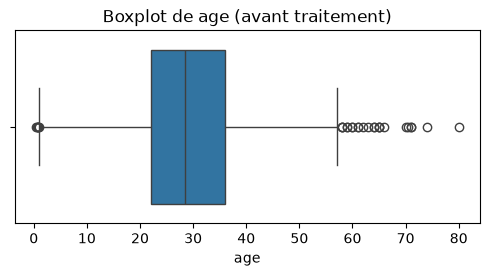

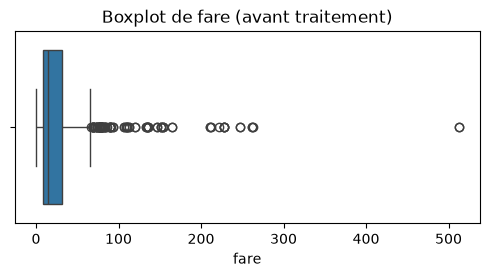

In [13]:
cols_out = ["age", "fare"]

for col in cols_out:
    plt.figure(figsize=(6, 2.5))
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot de {col} (avant traitement)")
    plt.show()

In [14]:
bornes = {}
for col in cols_out:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    L = Q1 - 1.5 * IQR
    U = Q3 + 1.5 * IQR
    med = X_train[col].median()
    bornes[col] = (L, U, med)
    n = ((X_train[col] < L) | (X_train[col] > U)).sum()
    print(f"{col}: L={L:.2f}, U={U:.2f}, médiane={med:.2f}, outliers={n}")

age: L=1.00, U=57.00, médiane=28.50, outliers=29
fare: L=-26.76, U=65.66, médiane=14.45, outliers=91


In [15]:
for col in cols_out:
    L, U, med = bornes[col]
    X_train[col] = X_train[col].where(X_train[col].between(L, U), med)
    X_test[col] = X_test[col].where(X_test[col].between(L, U), med)

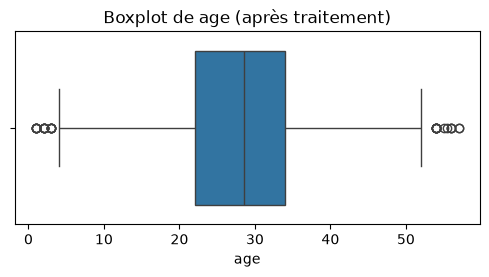

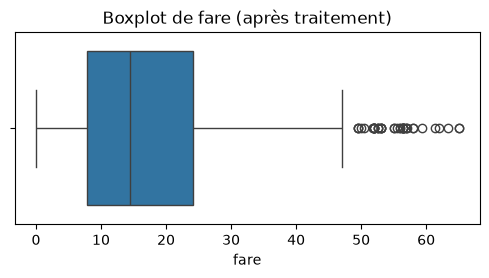

In [16]:
for col in cols_out:
    plt.figure(figsize=(6, 2.5))
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot de {col} (après traitement)")
    plt.show()

In [17]:
cols_redondantes = ["class", "who", "adult_male", "embark_town", "alive", "alone"]
cols_redondantes = [c for c in cols_redondantes if c in X_train.columns]

X_train = X_train.drop(columns=cols_redondantes)
X_test = X_test.drop(columns=cols_redondantes)

X_train.dtypes

pclass        int64
sex             str
age         float64
sibsp         int64
parch         int64
fare        float64
embarked        str
dtype: object

In [18]:
cols_cat = X_train.select_dtypes(exclude="number").columns.tolist()
print("Colonnes catégorielles :", cols_cat)

Colonnes catégorielles : ['sex', 'embarked']


In [19]:
from sklearn.preprocessing import OneHotEncoder

cols_nominales = ["sex", "embarked"]

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[cols_nominales])                 
noms = ohe.get_feature_names_out(cols_nominales)

def appliquer_ohe(X):
    codes = pd.DataFrame(ohe.transform(X[cols_nominales]), columns=noms, index=X.index)
    return pd.concat([X.drop(columns=cols_nominales), codes], axis=1)

X_train_enc = appliquer_ohe(X_train)
X_test_enc = appliquer_ohe(X_test)

X_train_enc.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
692,3,28.5,0,0,56.4958,0.0,1.0,0.0,0.0,1.0
481,2,28.5,0,0,0.0000,0.0,1.0,0.0,0.0,1.0
527,1,28.5,0,0,14.4542,0.0,1.0,0.0,0.0,1.0
855,3,18.0,0,1,9.3500,1.0,0.0,0.0,0.0,1.0
801,2,31.0,1,1,26.2500,1.0,0.0,0.0,0.0,1.0


In [20]:
X_train_enc["pclass"].unique()

array([3, 2, 1])

In [21]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cols_scale = ["age", "fare"]

mm = MinMaxScaler().fit(X_train_enc[cols_scale])   

X_train_mm = X_train_enc.copy()
X_test_mm = X_test_enc.copy()
X_train_mm[cols_scale] = mm.transform(X_train_enc[cols_scale])
X_test_mm[cols_scale] = mm.transform(X_test_enc[cols_scale])

In [22]:
sc = StandardScaler().fit(X_train_enc[cols_scale])  

X_train_std = X_train_enc.copy()
X_test_std = X_test_enc.copy()
X_train_std[cols_scale] = sc.transform(X_train_enc[cols_scale])
X_test_std[cols_scale] = sc.transform(X_test_enc[cols_scale])

In [23]:
print("Min-Max TRAIN :")
print(X_train_mm[cols_scale].agg(["min", "max"]))
print("\nMin-Max TEST :")
print(X_test_mm[cols_scale].agg(["min", "max"]))

print("\nZ-score TRAIN :")
print(X_train_std[cols_scale].agg(["mean"]).round(3))
print(X_train_std[cols_scale].std(ddof=0).round(3))

Min-Max TRAIN :
     age  fare
min  0.0   0.0
max  1.0   1.0

Min-Max TEST :
          age      fare
min  0.000000  0.000000
max  0.982143  0.941154

Z-score TRAIN :
      age  fare
mean  0.0   0.0
age     1.0
fare    1.0
dtype: float64


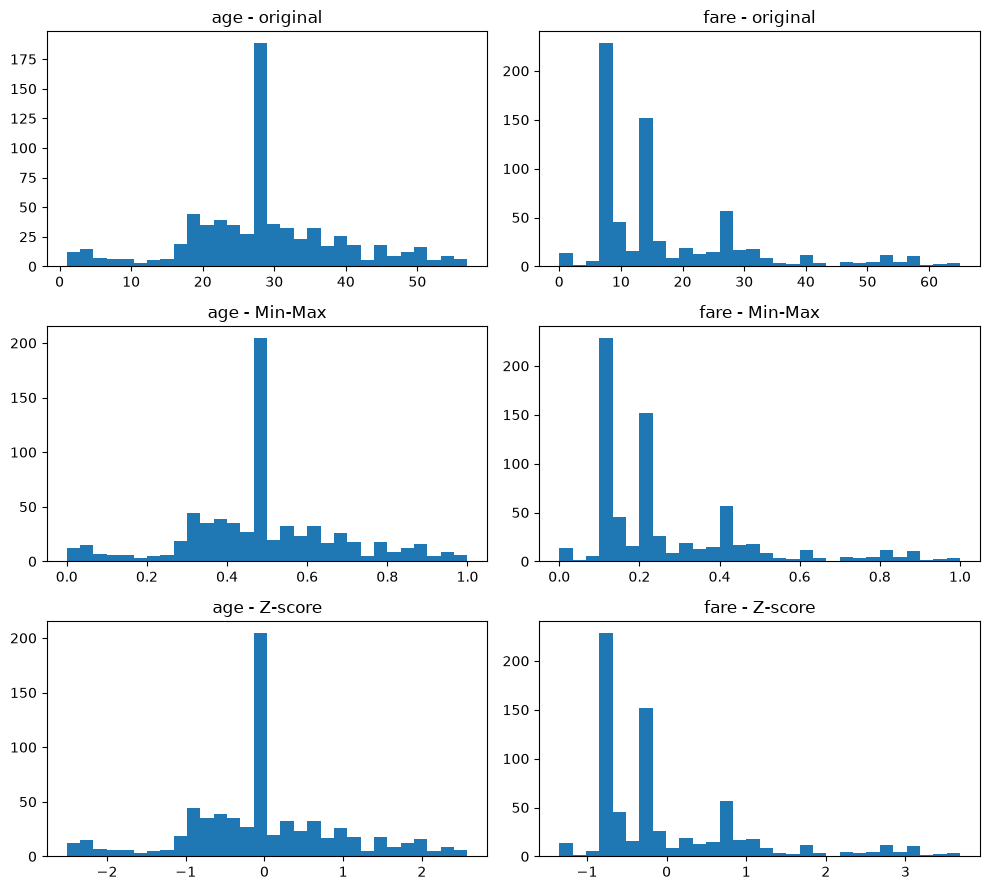

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(10, 9))

versions = [
    (X_train_enc, "original"),
    (X_train_mm, "Min-Max"),
    (X_train_std, "Z-score"),
]

for ligne, (data, nom) in enumerate(versions):
    for colonne, col in enumerate(cols_scale):
        axes[ligne, colonne].hist(data[col], bins=30)
        axes[ligne, colonne].set_title(f"{col} - {nom}")

plt.tight_layout()
plt.show()

In [25]:
print(y_train.value_counts())
print()
print((y_train.value_counts(normalize=True) * 100).round(1))

survived
0    439
1    273
Name: count, dtype: int64

survived
0    61.7
1    38.3
Name: proportion, dtype: float64


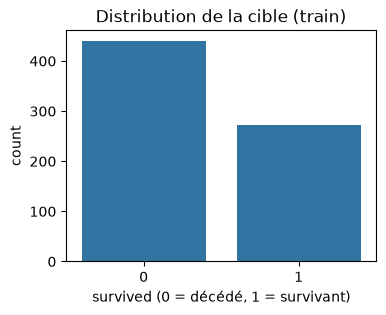

In [26]:
plt.figure(figsize=(4, 3))
sns.countplot(x=y_train)
plt.title("Distribution de la cible (train)")
plt.xlabel("survived (0 = décédé, 1 = survivant)")
plt.show()

In [27]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train_std, y_train)

print("Avant :", y_train.value_counts().to_dict())
print("Après undersampling :", y_train_under.value_counts().to_dict())
print("Taille :", len(y_train), "->", len(y_train_under))

Avant : {0: 439, 1: 273}
Après undersampling : {0: 273, 1: 273}
Taille : 712 -> 546


In [28]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_std, y_train)

print("Avant :", y_train.value_counts().to_dict())
print("Après SMOTE :", y_train_smote.value_counts().to_dict())
print("Taille :", len(y_train), "->", len(y_train_smote))

Avant : {0: 439, 1: 273}
Après SMOTE : {1: 439, 0: 439}
Taille : 712 -> 878


In [29]:
cols_ohe = [c for c in X_train_smote.columns if c.startswith(("sex_", "embarked_"))]
print(X_train_smote[cols_ohe].describe().loc[["min", "max"]])
print()
print("Valeurs différentes de 0 et 1 :",
      ((X_train_smote[cols_ohe] != 0) & (X_train_smote[cols_ohe] != 1)).sum().sum())

     sex_female  sex_male  embarked_C  embarked_Q  embarked_S
min         0.0       0.0         0.0         0.0         0.0
max         1.0       1.0         1.0         1.0         1.0

Valeurs différentes de 0 et 1 : 46


In [30]:
resume = pd.DataFrame({
    "Original": y_train.value_counts(),
    "Undersampling": y_train_under.value_counts(),
    "SMOTE": y_train_smote.value_counts(),
}).fillna(0).astype(int)
resume.loc["Total"] = resume.sum()
resume

,Original,Undersampling,SMOTE
survived,,,
0,439,273,439
1,273,273,439
Total,712,546,878


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def evaluer(X_tr, y_tr, nom):
    modele = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    pred = modele.predict(X_test_std)        
    return {
        "Version": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Rappel (survivants)": recall_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    }

resultats = pd.DataFrame([
    evaluer(X_train_std, y_train, "Sans rééquilibrage"),
    evaluer(X_train_under, y_train_under, "Undersampling"),
    evaluer(X_train_smote, y_train_smote, "SMOTE"),
]).round(3)
resultats

,Version,Accuracy,Rappel (survivants),Précision,F1
0,Sans rééquilibrage,0.782,0.667,0.742,0.702
1,Undersampling,0.782,0.797,0.688,0.738
2,SMOTE,0.788,0.754,0.712,0.732
